# Feature Selection using Reinforcement Learning — Replication
### Replicating Rasoul, Adewole & Akakpo (2021), *Feature Selection Using Reinforcement Learning*

This notebook implements the paper's MDP/TD(0) feature-selection method on the **Sonar (Connectionist Bench)** dataset and benchmarks it against the paper's reported result (**73.69% ± 10.8%**) and standard filter-based baselines.

**Fixes applied vs. earlier draft:**
- `header=None` on data load (sonar.all-data has no header row — this was silently dropping a sample and corrupting column names)
- Label column now encoded by position (`df[60]`) instead of relying on an accidental column name
- Full train/val/test split (no more picking the best feature-subset size using the same set used for final reporting)
- Entire pipeline wrapped in one function with fully local state (fixes the earlier bug where 5 "different" seed runs all returned the identical cached `best_accuracy`)
- Epsilon sweep (reproduces the paper's Figure 2)
- Full accuracy-vs-k sweep for RL **and** filter baselines (reproduces the paper's Figures 3–5)
- Multi-seed mean ± std, reported in the same format as the paper

**Notebook layout**
- **Part A — original replication (sections 1–8):** data, the single pipeline, one full run, Figure 1, the
  accuracy-vs-k plot, and the filter-method comparison. These produce the replication's results.
- **Part B — additional experiments (sections 9–10):** the epsilon sweep and the multi-seed evaluation. They are
  supplementary, store their output in `extra_*` variables, and never modify the Part A results.

## 1. Imports

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif, chi2
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

## 2. Load data

**Fix:** `sonar.all-data` has no header row — every row is a real sample.
Loading it without `header=None` silently treats the first sample as column names,
losing a row and corrupting your column labels.

In [ ]:
candidates = [
    r"C:\Users\91899\Downloads\sonar.all-data",
    '/content/sonar.all-data',
    'sonar.all-data',
    '/mnt/user-data/uploads/sonar.all-data',
]
DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("sonar.all-data not found. Add its location to `candidates` above.")

df = pd.read_csv(DATA_PATH, header=None)
print(df.shape)   # should be (208, 61)
df.sample(5)

(208, 61)


,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
161,0.0305,0.0363,0.0214,0.0227,0.0456,0.0665,0.0939,0.0972,0.2535,0.3127,...,0.0200,0.0070,0.0070,0.0086,0.0089,0.0074,0.0042,0.0055,0.0021,M
15,0.0298,0.0615,0.0650,0.0921,0.1615,0.2294,0.2176,0.2033,0.1459,0.0852,...,0.0031,0.0153,0.0071,0.0212,0.0076,0.0152,0.0049,0.0200,0.0073,R
73,0.0139,0.0222,0.0089,0.0108,0.0215,0.0136,0.0659,0.0954,0.0786,0.1015,...,0.0062,0.0072,0.0113,0.0012,0.0022,0.0025,0.0059,0.0039,0.0048,R
96,0.0181,0.0146,0.0026,0.0141,0.0421,0.0473,0.0361,0.0741,0.1398,0.1045,...,0.0223,0.0255,0.0145,0.0233,0.0041,0.0018,0.0048,0.0089,0.0085,R
166,0.0411,0.0277,0.0604,0.0525,0.0489,0.0385,0.0611,0.1117,0.1237,0.2300,...,0.0217,0.0038,0.0019,0.0065,0.0132,0.0108,0.0050,0.0085,0.0044,M


In [ ]:
df.isnull().sum().sum()  # sanity check: should be 0

np.int64(0)

## 3. Label encoding

**Fix:** encode the label column by its positional index (`60`), not by an
accidental column name that only existed because of the header bug above.

In [ ]:
le = LabelEncoder()
df[60] = le.fit_transform(df[60])   # R -> 0, M -> 1 (or vice versa, check le.classes_)
print(dict(zip(le.classes_, le.transform(le.classes_))))

X_full = df.iloc[:, :60].values
y_full = df[60].values
n_features = X_full.shape[1]

{'M': np.int64(0), 'R': np.int64(1)}


## 4. The full pipeline, as one self-contained function

Everything — split, scaling, reward function, `V` table, `AOR` table, the TD(0) episode
loop, and final evaluation — lives inside this single function with fully local state.
This is the **only** pipeline implementation in the notebook; all later sections call it.

**Data split (no leakage):**
- `train` (60%) — used to fit each candidate SVM during RL training. The scaler used *during the search* is fitted
  on `train` only, because every SVM in the search is trained on `train`.
- `val` (20%) — used as the **reward signal** during training, and to pick the best
  feature-subset size (`best_k`) afterwards
- `test` (20%) — held out completely, touched **only** for the final reported accuracy

**Final model:** once the subset is chosen, the final SVM is trained on `train + val`, so its scaler is **re-fitted on
`train + val`** (inside a `Pipeline`) and then applied to the test set. The train-only scaler from the search is
not reused for the final model.

**Formulas implemented:**
- Eq. 1 (reward = accuracy delta) → `reward = next_acc - current_acc`
- Eq. 4 (TD(0) update) → `V[state] = v + alpha*(reward + gamma*v_next - v)`
- Eq. 6 (AOR incremental update) → `update_AOR()`
- Eq. 7 (greedy action via AOR) → the `epsilon`-greedy branch below

**AOR implementation retained:** Eq. 6 taken literally, averaging `V(next_state)` each step. The paper's Eq. 5 and
Eq. 6 are not mutually consistent; see the AOR diagnostic in section 5 for the ambiguity and its practical effect.

In [ ]:
def run_full_pipeline(
    seed,
    n_episodes=200,
    alpha=0.1,
    gamma=0.9,
    epsilon=0.5,
    verbose=False,
    evaluate_test=True
):    # --- 60/20/20 train/val/test split, fresh for this seed ---
    X_trainval, X_test, y_trainval, y_test = train_test_split(
        X_full, y_full, test_size=0.2, random_state=seed, stratify=y_full)
    X_train, X_val, y_train, y_val = train_test_split(
        X_trainval, y_trainval, test_size=0.25, random_state=seed, stratify=y_trainval)  # 0.25*0.8 = 0.2

    # --- Scaler for the RL SEARCH: fitted on `train` only (every SVM in the search trains on `train`) ---
    scaler = StandardScaler().fit(X_train)
    X_train_s = scaler.transform(X_train)
    X_val_s = scaler.transform(X_val)

    # --- Fresh learning state (local, not global) ---
    V = {}
    AOR = {f: {"count": 0, "value": 0.0} for f in range(n_features)}
    reward_cache = {}

    def get_reward(subset):
        """Reward signal during training = validation accuracy (never touches test set)."""
        if len(subset) == 0:
            return 0.0
        key = frozenset(subset)
        if key in reward_cache:
            return reward_cache[key]
        idx = sorted(subset)
        clf = SVC(kernel='rbf', gamma='scale')
        clf.fit(X_train_s[:, idx], y_train)
        preds = clf.predict(X_val_s[:, idx])
        acc = np.mean(preds == y_val)
        reward_cache[key] = acc
        return acc

    def get_state_value(state):
        return V.get(state, 0.0)

    def update_AOR(feature, state_value_difference):
        entry = AOR[feature]
        entry["count"] += 1
        k = entry["count"]

        entry["value"] = (
            (k - 1) * entry["value"] + state_value_difference
        ) / k

    rng = random.Random(seed)
    all_features = set(range(n_features))
    max_value_per_episode = []
    states_visited_per_episode = []
    revisit_steps = total_steps = 0          # diagnostic counters, recorded by the pipeline itself

    # --- TD(0) training loop ---
    for ep in range(n_episodes):
        current_state = frozenset(rng.sample(list(all_features), k=rng.randint(1, 5)))
        current_acc = get_reward(current_state)
        episode_max_value = get_state_value(current_state)

        while current_state != frozenset(all_features):
            remaining = list(all_features - current_state)
            total_steps += 1

            # two-phase action selection (paper Section 4.2)
            if current_state not in V:
                action = rng.choice(remaining)                       # random-based phase
            else:
                revisit_steps += 1
                if rng.random() < epsilon:
                    action = rng.choice(remaining)                   # exploration
                else:
                    action = max(remaining, key=lambda f: AOR[f]["value"])  # Eq. 7, epsilon-greedy phase

            next_state = frozenset(current_state | {action})
            next_acc = get_reward(next_state)

            reward = next_acc - current_acc                          # Eq. 1
            v_cur = get_state_value(current_state)
            v_next = get_state_value(next_state)
            V[current_state] = v_cur + alpha * (reward + gamma * v_next - v_cur)  # Eq. 4
            update_AOR(action, v_cur - v_next)                                # Eq. 6

            current_state = next_state
            current_acc = next_acc
            episode_max_value = max(episode_max_value, get_state_value(current_state))

        max_value_per_episode.append(episode_max_value)
        states_visited_per_episode.append(len(V))

    # --- Extract best feature subset via AOR ranking, sized using VALIDATION accuracy ---
    ranked_features = sorted(AOR.keys(), key=lambda f: AOR[f]["value"], reverse=True)
    val_accuracies = [get_reward(ranked_features[:k]) for k in range(1, n_features + 1)]
    best_k = int(np.argmax(val_accuracies)) + 1
    best_subset = ranked_features[:best_k]
    best_val_acc = val_accuracies[best_k - 1]

    # --- FINAL model: scaler re-fitted on the SAME data the final model trains on (train + val) ---
    # The search scaler above was fitted on `train` only. Reusing it to transform train+val would hand the final
    # model inputs that are not standardised with respect to its own training data. The Pipeline fits scaler and
    # SVM together on train+val; the test set is only transformed/predicted, never used to fit anything.
    def final_test_accuracy(subset):
        """Fit scaler+SVM on train+val using `subset`, score once on the held-out test set."""
        idx = sorted(int(f) for f in subset)
        model = make_pipeline(StandardScaler(), SVC(kernel='rbf', gamma='scale'))
        model.fit(X_trainval[:, idx], y_trainval)
        return float(np.mean(model.predict(X_test[:, idx]) == y_test))

    test_acc = (
        final_test_accuracy(best_subset)
        if evaluate_test
        else np.nan
    )          # the single test evaluation for the RL-selected subset

    if verbose:
        print(
            f"seed={seed} | epsilon={epsilon} | "
            f"best_k={best_k} | "
            f"val_acc={best_val_acc:.4f} | "
            f"test_acc={test_acc:.4f}"
            if evaluate_test
            else
            f"seed={seed} | epsilon={epsilon} | "
            f"best_k={best_k} | "
            f"val_acc={best_val_acc:.4f} | test evaluation skipped"
        )

    return dict(
        seed=seed, best_k=best_k, best_subset=best_subset,
        best_val_acc=best_val_acc, test_acc=test_acc,
        V=V, AOR=AOR, ranked_features=ranked_features, val_accuracies=val_accuracies,
        max_value_per_episode=max_value_per_episode,
        states_visited_per_episode=states_visited_per_episode,
        revisit_rate=revisit_steps / total_steps,
        # handed to the baseline comparison so every method uses the SAME evaluators and the SAME training data
        X_train_s=X_train_s, y_train=y_train,
        val_accuracy=get_reward, final_test_accuracy=final_test_accuracy,
    )

## 5. Run one full training pass and inspect the result

In [ ]:
result = run_full_pipeline(seed=RANDOM_STATE, n_episodes=200, epsilon=0.5, verbose=True)

print(f"\nBest subset size: {result['best_k']}")
print(f"Selected features: {result['best_subset']}")
print(f"Validation accuracy (used to pick k): {result['best_val_acc']:.4f}")
print(f"Held-out TEST accuracy (final, reported): {result['test_acc']:.4f}")
print(f"Paper's reported Sonar accuracy: 0.7369 +/- 0.108")

# Freeze the original replication's output. Part B (additional experiments) writes only to `extra_*` variables and is
# checked against this snapshot at the end of the notebook.
replication_result = result
replication_summary = dict(seed=result['seed'], best_k=result['best_k'],
                           best_subset=list(result['best_subset']),
                           best_val_acc=float(result['best_val_acc']), test_acc=float(result['test_acc']))

seed=42 | epsilon=0.5 | best_k=24 | val_acc=0.8571 | test_acc=0.8095

Best subset size: 24
Selected features: [9, 11, 19, 10, 35, 8, 21, 33, 2, 32, 24, 20, 55, 26, 50, 52, 29, 15, 57, 4, 5, 13, 16, 27]
Validation accuracy (used to pick k): 0.8571
Held-out TEST accuracy (final, reported): 0.8095
Paper's reported Sonar accuracy: 0.7369 +/- 0.108


### AOR diagnostic and the Eq. 5 / Eq. 6 ambiguity

The paper defines AOR twice, and the two definitions disagree:
- **Eq. 5:** AOR is the average of `V(F_t) - V(F_t+1)`, a *difference* of two state values.
- **Eq. 6:** the incremental update `[(k-1)·AOR_old + V(F)] / k` has room for only a *single* value `V(F)`.

**Retained implementation:** Eq. 6 literally, averaging `V(next_state)` (`update_AOR(action, v_next)` inside the pipeline).
That is the only one of the two that is directly computable as written.

**The diagnostic below does not re-implement anything.** It reads the output of the same run and the same `AOR`
table the pipeline produced, so it cannot drift from the retained implementation.

**Why it matters on Sonar:** `V(next_state)` is exactly 0 whenever the next state has never been updated before, and
on a 2^60-state space almost every step enters a brand-new state. AOR entries therefore stay at exactly 0 unless a
transition happens to land on an already-updated state. Python's `sorted(..., reverse=True)` is stable, so features
with equal AOR keep their original index order, which means that part of the ranking is a tie-break by feature number,
not learned preference. The counts below show how large that part is.

In [ ]:
aor_values = np.array([result['AOR'][f]['value'] for f in range(n_features)])
aor_counts = np.array([result['AOR'][f]['count'] for f in range(n_features)])

print(f"Share of steps that revisited a known state       : {result['revisit_rate']:.2%}")
print(f"Features with AOR exactly 0.0 (ranked by tie-break): {(aor_values == 0).sum()} of {n_features}")
print(f"Features with AOR > 0 / AOR < 0                    : {(aor_values > 0).sum()} / {(aor_values < 0).sum()}")
print(f"Times a feature was chosen as an action            : min {aor_counts.min()}, max {aor_counts.max()}")
print(f"Selected subset (best_k={result['best_k']}) contains {sum(aor_values[f] != 0 for f in result['best_subset'])} "
      f"feature(s) with a non-zero AOR")

Share of steps that revisited a known state       : 1.40%
Features with AOR exactly 0.0 (ranked by tie-break): 9 of 60
Features with AOR > 0 / AOR < 0                    : 20 / 31
Times a feature was chosen as an action            : min 182, max 197
Selected subset (best_k=24) contains 20 feature(s) with a non-zero AOR


## 6. Figure 1 equivalent — max state value per episode

1.   List item
2.   List item



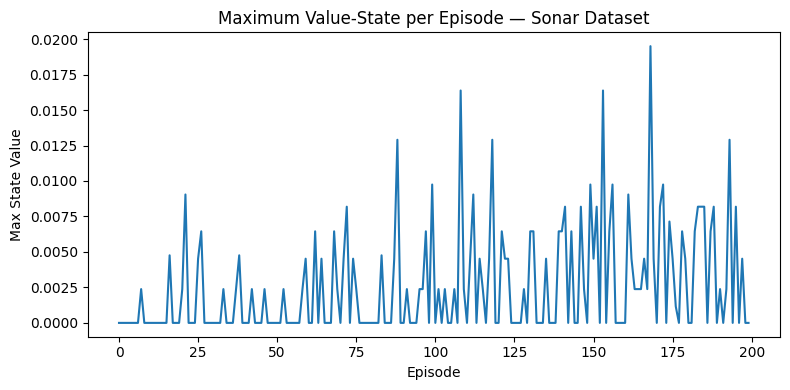

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(result['max_value_per_episode'])
plt.title("Maximum Value-State per Episode — Sonar Dataset")
plt.xlabel("Episode")
plt.ylabel("Max State Value")
plt.tight_layout()
plt.show()

## 7. Accuracy vs. number of selected features (elbow plot for best_k)

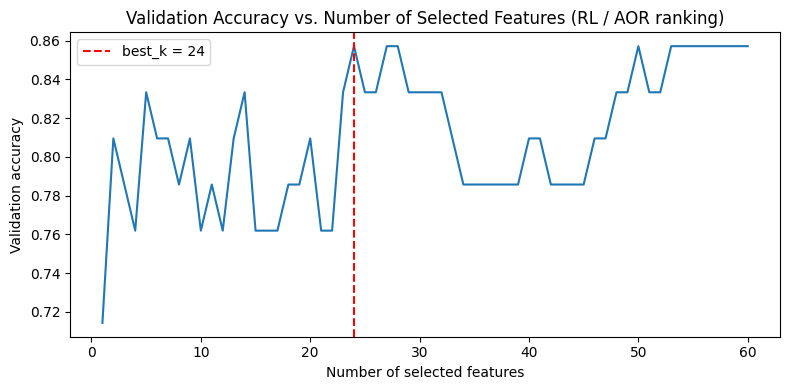

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_features + 1), result['val_accuracies'])
plt.axvline(result['best_k'], color='red', linestyle='--', label=f"best_k = {result['best_k']}")
plt.title("Validation Accuracy vs. Number of Selected Features (RL / AOR ranking)")
plt.xlabel("Number of selected features")
plt.ylabel("Validation accuracy")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Filter-method comparison — reproduces the paper's Figures 3–5

Compares the RL/AOR feature ranking against Chi-squared, Mutual Information
(Information Gain), and Random Forest importance, across the **full range** of
subset sizes — not just a single fixed k.

**Test-set discipline in this section**
- Every ranking is computed from the **training portion only**.
- The accuracy-vs-k curves and each method's chosen `k` come from the **validation** set, using the same
  train → validation evaluator the RL agent used. The test set is **not** evaluated at every `k`.
- The test set is evaluated **once per method**, only for that method's final chosen subset (plus once for all 60
  features as a reference).
- Caveat: the RL agent's reward *was* validation accuracy, so RL has a built-in advantage on the validation curve.
  The test column of the final table is the fair comparison.

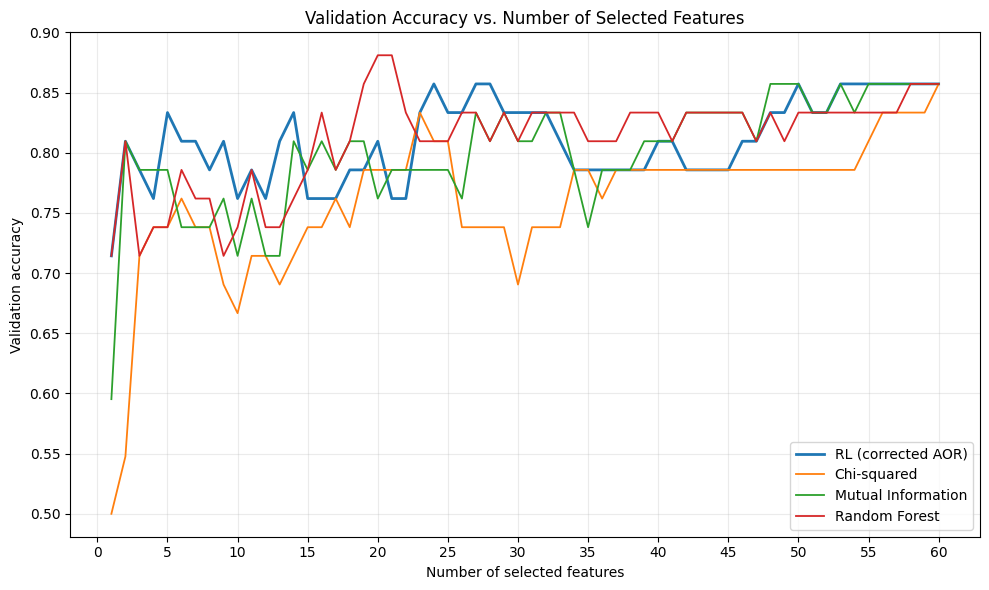

,Method,Selected features,Feature reduction (%),Validation accuracy,Test accuracy
0,RL (corrected AOR),24,60.00,0.8571,0.8095
1,Chi-squared,60,0.00,0.8571,0.8571
2,Mutual Information,48,20.00,0.8571,0.8571
3,Random Forest,20,66.67,0.8810,0.8571
4,All 60 features,60,0.00,0.8571,0.8571


Important: feature counts are selected using validation accuracy. The test set is used only for final evaluation.
RL uses validation accuracy as its reward, so the held-out test results are the more appropriate basis for comparison.


In [ ]:

# SECTION 8 — Filter-method comparison (corrected-AOR run)

X_tr_s = result['X_train_s']
y_tr = result['y_train']

val_accuracy = result['val_accuracy']
final_test_accuracy = result['final_test_accuracy']

# --------------------------------------------------
# 1. Generate feature rankings using training data only
# --------------------------------------------------
rankings = {
    "RL (corrected AOR)": list(result['ranked_features']),

    "Chi-squared": list(
        np.argsort(
            chi2(MinMaxScaler().fit_transform(X_tr_s), y_tr)[0]
        )[::-1]
    ),

    "Mutual Information": list(
        np.argsort(
            mutual_info_classif(
                X_tr_s, y_tr, random_state=RANDOM_STATE
            )
        )[::-1]
    ),

    "Random Forest": list(
        np.argsort(
            RandomForestClassifier(
                n_estimators=300,
                random_state=RANDOM_STATE
            ).fit(X_tr_s, y_tr).feature_importances_
        )[::-1]
    )
}

# --------------------------------------------------
# 2. Calculate validation accuracy for every k
# --------------------------------------------------
def validation_curve(ranking):
    ranking = [int(f) for f in ranking]

    assert sorted(ranking) == list(range(n_features)), (
        "Ranking must contain every feature exactly once."
    )

    return [
        val_accuracy(ranking[:k])
        for k in range(1, n_features + 1)
    ]

val_curves = {
    name: validation_curve(ranking)
    for name, ranking in rankings.items()
}

# Confirm RL ranking matches the pipeline's saved curve
assert np.allclose(
    val_curves["RL (corrected AOR)"],
    result["val_accuracies"]
), "RL curve differs from the pipeline's saved curve."

# --------------------------------------------------
# 3. Plot validation accuracy vs. selected features
# --------------------------------------------------
plt.figure(figsize=(10, 6))

for name, curve in val_curves.items():
    plt.plot(
        range(1, n_features + 1),
        curve,
        label=name,
        linewidth=2 if name == "RL (corrected AOR)" else 1.3
    )

plt.title("Validation Accuracy vs. Number of Selected Features")
plt.xlabel("Number of selected features")
plt.ylabel("Validation accuracy")
plt.xticks(range(0, n_features + 1, 5))
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 4. Select k using validation, then evaluate test once
# --------------------------------------------------
rows = []

for name, ranking in rankings.items():
    curve = val_curves[name]
    best_k = int(np.argmax(curve)) + 1
    selected = ranking[:best_k]

    test_acc = final_test_accuracy(selected)

    rows.append({
        "Method": name,
        "Selected features": best_k,
        "Feature reduction (%)": round(
            100 * (1 - best_k / n_features), 2
        ),
        "Validation accuracy": round(float(curve[best_k - 1]), 4),
        "Test accuracy": round(float(test_acc), 4)
    })

# All-features reference baseline
all_features = list(range(n_features))

rows.append({
    "Method": "All 60 features",
    "Selected features": n_features,
    "Feature reduction (%)": 0.0,
    "Validation accuracy": round(
        float(val_accuracy(all_features)), 4
    ),
    "Test accuracy": round(
        float(final_test_accuracy(all_features)), 4
    )
})

comparison = pd.DataFrame(rows)
display(comparison)

print(
    "Important: feature counts are selected using validation accuracy. "
    "The test set is used only for final evaluation."
)
print(
    "RL uses validation accuracy as its reward, so the held-out test "
    "results are the more appropriate basis for comparison."
)


---
# Part B — Additional experiments (separate from the original replication)

Everything from here down is **supplementary**. It re-runs the pipeline with other settings or seeds and stores its
output in variables prefixed `extra_`, so it never touches `result` / `replication_result`. The original replication is
sections 1–8 above, and a check at the end of the notebook confirms it was not altered.

## 9. Additional experiment — epsilon sweep (the paper's Figure 2)

*Additional experiment; not part of the original replication result.*

The paper studies how the number of states visited changes with epsilon
(0.3, 0.4, 0.5, 0.6) — higher epsilon means more exploration, more states visited.
Epsilon only matters when the agent revisits a state, so the revisit rate is printed alongside.

In [ ]:
# STEP 3: EPSILON EXPERIMENT
# Compare exploration for different epsilon values.

epsilon_values = [0.3, 0.4, 0.5, 0.6]
N_EPISODES_EPSILON = 150

epsilon_results = {}

for eps in epsilon_values:
    print(f"\nRunning experiment for epsilon = {eps}")

    epsilon_results[eps] = run_full_pipeline(
        seed=RANDOM_STATE,
        n_episodes=N_EPISODES_EPSILON,
        epsilon=eps,
        verbose=False,
        evaluate_test=False
    )

print("\nEpsilon experiment completed.")


Running experiment for epsilon = 0.3

Running experiment for epsilon = 0.4

Running experiment for epsilon = 0.5

Running experiment for epsilon = 0.6

Epsilon experiment completed.


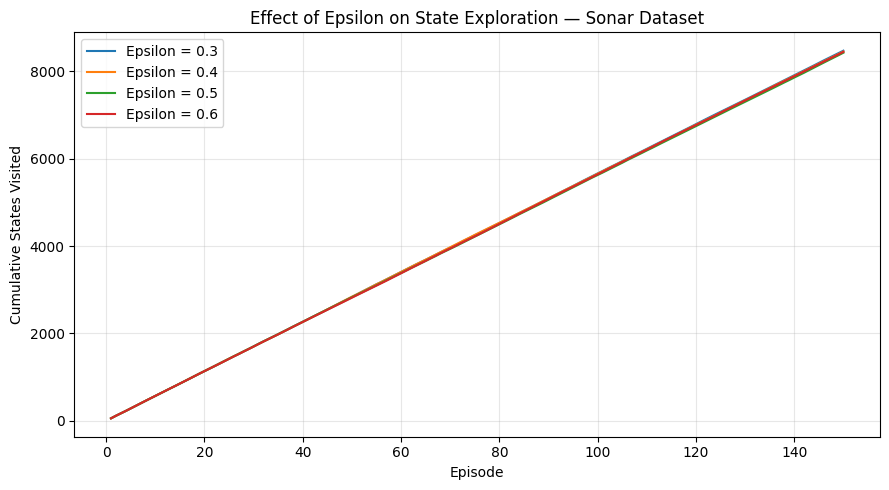

In [ ]:
# Plot cumulative number of states visited across episodes.

plt.figure(figsize=(9, 5))

for eps, res in epsilon_results.items():
    plt.plot(
        range(1, len(res["states_visited_per_episode"]) + 1),
        res["states_visited_per_episode"],
        label=f"Epsilon = {eps}"
    )

plt.title("Effect of Epsilon on State Exploration — Sonar Dataset")
plt.xlabel("Episode")
plt.ylabel("Cumulative States Visited")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Additional experiment — multi-seed evaluation

*Additional experiment; not part of the original replication result.*

The paper reports a single mean ± std per dataset. This repeats the whole pipeline across independent seeds
(fresh split + fresh agent each time) to see how much a single run varies. The original replication's
single-run result (section 5) is unchanged by this.

In [ ]:
N_SEEDS = 10
extra_seed_results = [run_full_pipeline(seed=s, n_episodes=200, epsilon=0.5, verbose=True) for s in range(N_SEEDS)]
extra_test_accs = [res['test_acc'] for res in extra_seed_results]
extra_best_ks = [res['best_k'] for res in extra_seed_results]

print(f"\nTest accuracies: {[round(a, 4) for a in extra_test_accs]}")
print(f"Selected subset sizes: {extra_best_ks}")
print(f"\n=== ADDITIONAL EXPERIMENT: multi-seed result ===")
print(f"Multi-seed ({N_SEEDS} seeds): {np.mean(extra_test_accs):.4f} +/- {np.std(extra_test_accs):.4f}")
print(f"Paper's reported result:      0.7369 +/- 0.1080")

In [ ]:
# Guard: the additional experiments above must not have changed the original replication's output.
assert result is replication_result, "`result` was rebound after the replication run"
assert (result['seed'], result['best_k'], list(result['best_subset'])) == \
       (replication_summary['seed'], replication_summary['best_k'], replication_summary['best_subset'])
assert float(result['test_acc']) == replication_summary['test_acc']
print("OK: the original replication results are intact "
      f"(best_k={replication_summary['best_k']}, test_acc={replication_summary['test_acc']:.4f}).")

## 11. Notes on faithfulness to the paper's formulas

| Equation | Status |
|---|---|
| Eq. 1 — Reward = accuracy delta | Implemented exactly |
| Eq. 2 — Optimal policy (argmax reward) | Implemented via Eq. 7's AOR-based rule |
| Eq. 3 — Overall objective (minimize error) | Conceptual; satisfied implicitly by using SVM accuracy as reward |
| Eq. 4 — TD(0) state-value update | Implemented exactly |
| Eq. 5 — AOR as average of *value differences* | Not directly implementable — inconsistent with Eq. 6 in the source paper (see below) |
| Eq. 6 — AOR incremental update | Implemented exactly as written (the retained AOR implementation) |
| Eq. 7 — Greedy feature selection via AOR | Implemented exactly |

**On Eq. 5 vs Eq. 6:** the paper defines AOR as the average of a *difference* between
consecutive state values (Eq. 5), but its own incremental update formula (Eq. 6) only
has room for a single `V(F)` term, not a difference. We implement Eq. 6 literally,
folding in `V(next_state)` on each step, since it is the only one of the two that is
directly computable as written. This is a known internal inconsistency in the source
paper's notation, not an implementation gap.

**Methodological additions beyond the paper** (the paper does not describe these, but
they're standard good practice and make the reported numbers more defensible):
- 3-way train/val/test split, so the feature-subset size is never chosen using the same
  data used for the final reported accuracy
- Multi-seed mean ± std instead of a single run
- The final model's scaler is re-fitted on the data the final model trains on (train + val), inside a `Pipeline`
- The test set is evaluated only for final selected subsets (once per method), never across all feature counts
- Part A (sections 1–8) is the original replication; Part B (sections 9–10) holds additional experiments that cannot
  overwrite it